# 05 · Final pipeline

**Accelerator: GPU T4 x2** Inputs: competition data, `vd-utils`, outputs of notebooks `00`–`04` (the reference RT-DETR run and the results of all earlier models).
One "Save & Run All" runs the whole pipeline (~2.5 h). Runs that already exist in an attached output are not retrained, so a failed version can be resumed by attaching its output.

**Why RT-DETR.** Under the same 0.41 h budget, RT-DETR-L with 500 queries (`rtdetr_1024_q500`, notebook 04) is the best detector on every metric:
holdout mAP 0.317 vs 0.224–0.240 for YOLOv8s, RetinaNet and Faster R-CNN, `AP_small` 0.148 vs ≤ 0.100, and public LB 0.341 vs ≤ 0.227.
It reached its plateau after ~0.15 h, so the comparison is not limited by convergence. The final pipeline therefore keeps its settings (1024 px, 500 queries) and asks whether a larger model, more varied data and the test input size improve it further.

**Experiments.** Each run changes one thing relative to the reference; all runs get the same training time (0.41 h on 2×T4), so the model and data effects are compared at equal compute:

| block | run | model | training frames | question |
|---|---|---|---|---|
| reference | `rtdetr_1024_q500` (nb 04) | RT-DETR-L | step 10 (2 161) | – |
| **model** | `rtdetr_x_1024_q500` | **RT-DETR-X** (2.2× FLOPs) | step 10 | is a larger model better at the same compute (fewer epochs)? |
| **data** | `rtdetr_1024_q500_s5` | RT-DETR-L | **step 5 (4 322)** | is twice the frame variety better at the same compute (same steps, fewer repeats per frame)? |
| **inference** | – | best of the three | – | test input size 896 / 1024 / 1280 (no retraining; RT-DETR has no NMS to tune) |
| final | `final_full` | best of the three | its step, **all 63 clips** | same recipe on all labelled clips, time scaled by the number of frames |

Training recipe as in notebook 04 (Ultralytics defaults: AdamW, warmup, mosaic, scale ±50 %, flips, HSV), seed 42.

In [1]:
import os, re, sys, glob, gc, json, time, zipfile, subprocess, traceback
os.environ["YOLO_VERBOSE"] = "False"           # no per-iteration progress bars in the saved notebook
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
try:
    import pycocotools
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import ultralytics
from ultralytics import RTDETR, settings
settings.update({"wandb": False})
os.environ["WANDB_MODE"] = "disabled"

def find_utils():
    if os.path.exists("vd_utils.py"):
        return "."
    for depth in range(1, 6):
        hits = glob.glob(os.path.join("/kaggle/input", *["*"] * depth, "vd_utils.py"))
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError("Add the vd-utils dataset as notebook input")

sys.path.insert(0, find_utils())
import vd_utils as U

print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| GPUs", torch.cuda.device_count())

ultralytics 8.4.208 | torch 2.11.0+cu130 | GPUs 2


In [2]:
# --- Configuration --------------------------------------------------------------
SEED = 42
VAL_FOLD = 0
TIME_H, IMGSZ, WORKERS = 0.41, 1024, 4          # same budget and input size as notebook 04
DEVICE = [0, 1] if torch.cuda.device_count() > 1 else 0
CONF = 0.001
WORK = "/kaggle/working"
REF = "rtdetr_1024_q500"                         # reference run from notebook 04

def q500(scale):
    # model file with a 500-query decoder (RTDETRDecoder args: [nc, hidden_dim, num_queries])
    src = os.path.join(os.path.dirname(ultralytics.__file__), "cfg", "models", "rt-detr", f"rtdetr-{scale}.yaml")
    text, n = re.subn(r"RTDETRDecoder,\s*\[nc[^\]]*\]", "RTDETRDecoder, [nc, 256, 500]", open(src).read())
    assert n == 1, f"decoder line not found in {src}"
    path = f"{WORK}/rtdetr-{scale}-q500.yaml"
    open(path, "w").write(text)
    return path

RUNS = {   # step = training frame step; folds: "train" = folds != VAL_FOLD
    "rtdetr_x_1024_q500":  dict(model=q500("x"), pretrained="rtdetr-x.pt", step=10, folds="train", batch=4),
    "rtdetr_1024_q500_s5": dict(model=q500("l"), pretrained="rtdetr-l.pt", step=5,  folds="train", batch=8),
}
REF_CFG = dict(model=q500("l"), pretrained="rtdetr-l.pt", step=10, folds="train", batch=8)

# public leaderboard scores of earlier submissions (add new ones after submitting)
LB = {"v8s_640": 0.2085, "v8s_1024": 0.2271, "frcnn_base": 0.2190, "frcnn_props": 0.2184,
      "retina_base": 0.1806, "rtdetr_1024_q500": 0.3414}
U.seed_everything(SEED)
os.makedirs(f"{WORK}/results", exist_ok=True)

## Data

In [3]:
# --- Training lists per data configuration and the shared holdout ---------------------------
frames, anns = U.load_prep()
all_folds = sorted(frames.fold.unique())
train_folds = [f for f in all_folds if f != VAL_FOLD]
va = U.select_frames(frames, folds=VAL_FOLD, step=10)
val_paths = U.orig_image_paths(va)
gt_json, key2id = U.make_coco_gt(va, anns, f"{WORK}/gt_val.json")
val_ids = [key2id[k] for k in va.key]

def data_yaml_for(step, folds):
    tr = U.select_frames(frames, folds=train_folds if folds == "train" else all_folds, step=step)
    return U.write_yolo_data(U.train_image_paths(tr), val_paths, out_dir=f"{WORK}/yolo_data_s{step}_{folds}"), len(tr)

for cfg in list(RUNS.values()) + [REF_CFG]:
    cfg["data"], cfg["n_train"] = data_yaml_for(cfg["step"], cfg["folds"])
pd.DataFrame({**RUNS, REF: REF_CFG}).T[["pretrained", "step", "folds", "n_train", "batch"]]

,pretrained,step,folds,n_train,batch
rtdetr_x_1024_q500,rtdetr-x.pt,10,train,2161,4
rtdetr_1024_q500_s5,rtdetr-l.pt,5,train,4297,8
rtdetr_1024_q500,rtdetr-l.pt,10,train,2161,8


In [4]:
# --- Helpers: locate runs (this session or attached outputs), train, predict, evaluate --------
def run_dir(name):
    if os.path.exists(f"{WORK}/runs/{name}/weights/last.pt"):
        return f"{WORK}/runs/{name}"
    for top in sorted(os.listdir("/kaggle/input")) if os.path.isdir("/kaggle/input") else []:
        if top == "competitions" or U.COMP_SLUG in top:
            continue
        for dirpath, dirnames, filenames in os.walk(os.path.join("/kaggle/input", top)):
            dirnames[:] = [d for d in dirnames if d not in ("train_masked", "images", "labels")]
            if dirpath.endswith(os.path.join("runs", name, "weights")) and "last.pt" in filenames:
                return os.path.dirname(dirpath)
    return None

def weights(name, holdout=True):
    # holdout runs: best epoch as in notebook 04; a run on all clips has no holdout, so its last epoch
    d = run_dir(name)
    return f"{d}/weights/best.pt" if holdout and os.path.exists(f"{d}/weights/best.pt") else f"{d}/weights/last.pt"

def train(name, cfg, time_h):
    if run_dir(name) is not None:
        print(f"{name}: found, skipped")
        return
    t0 = time.time()
    try:
        RTDETR(cfg["model"]).train(
            data=cfg["data"], imgsz=IMGSZ, pretrained=cfg["pretrained"], time=time_h, epochs=100,
            batch=cfg["batch"], device=DEVICE, workers=WORKERS, seed=SEED, max_det=U.MAX_DET, close_mosaic=5,
            cache="ram", val=cfg["folds"] == "train", project=f"{WORK}/runs", name=name, exist_ok=True,
            plots=False, verbose=False)
    except Exception:
        traceback.print_exc()           # keep going: finished runs stay in the output
        return
    hours = round((time.time() - t0) / 3600, 2)
    keep = {k: v for k, v in cfg.items() if k != "data"}
    with open(f"{WORK}/runs/{name}/train_info.json", "w") as f:
        json.dump({"train_hours": hours, "time_budget_h": time_h, **keep}, f)
    print(f"{name}: {hours} h, {cfg['n_train']} frames")

def predict(model, source, imgsz=IMGSZ):
    return model.predict(source, imgsz=imgsz, conf=CONF, max_det=U.MAX_DET, device=0, verbose=False)

def boxes_of(r):
    b = r.boxes
    return b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int)

def evaluate(model, imgsz=IMGSZ):
    dets = []
    for img_id, p in zip(val_ids, val_paths):
        dets += U.to_coco_dets(img_id, *boxes_of(predict(model, p, imgsz)[0]))
    m = U.coco_evaluate(gt_json, dets)
    m["FPS"] = round(U.measure_fps(lambda p: predict(model, p, imgsz), val_paths[:70], warmup=10, n=60), 1)
    return m

## Model vs data: training under the same budget

In [5]:
# --- Train the model and data experiments ---------------------------------------------------
for name, cfg in RUNS.items():
    train(name, cfg, TIME_H)

train: Caching images (6.3GB RAM): 100% ━━━━━━━━━━━━ 2161/2161 31.3it/s 1:09
val: Caching images (1.7GB RAM): 100% ━━━━━━━━━━━━ 573/573 71.0it/s 8.1s


rtdetr_x_1024_q500: 0.49 h, 2161 frames
train: Caching images (12.6GB RAM): 100% ━━━━━━━━━━━━ 4297/4297 39.9it/s 1:48
val: Caching images (1.7GB RAM): 100% ━━━━━━━━━━━━ 573/573 98.6it/s 5.8s


rtdetr_1024_q500_s5: 0.54 h, 4297 frames


In [6]:
# --- Holdout results; the reference is re-evaluated from notebook 04's weights -----------------
results = {}
for name in [REF] + list(RUNS):
    if run_dir(name) is None:
        print(f"{name}: not found")
        continue
    try:
        gc.collect(); torch.cuda.empty_cache()
        results[name] = evaluate(RTDETR(weights(name)))
    except Exception:
        traceback.print_exc()
        continue
    info = os.path.join(run_dir(name), "train_info.json")
    results[name]["train_h"] = json.load(open(info))["train_hours"] if os.path.exists(info) else float("nan")
    with open(f"{WORK}/results/{name}.json", "w") as f:
        json.dump(results[name], f)

res = pd.DataFrame(results).T
display(res[["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500", "FPS", "train_h"]])
display(res[[f"AP_{c}" for c in U.CLASSES]])
if REF in res.index:
    gain = (res[["mAP", "AP_small", "AR500"]] - res.loc[REF, ["mAP", "AP_small", "AR500"]]).drop(REF)
    display(gain.rename(columns=lambda c: f"Δ{c} vs {REF}").round(4))

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,FPS,train_h
rtdetr_1024_q500,0.3166,0.5723,0.3109,0.1480,0.2814,0.5223,0.4937,6.9,0.46
rtdetr_x_1024_q500,0.3053,0.5575,0.2957,0.1441,0.2815,0.5225,0.4975,3.9,0.49
rtdetr_1024_q500_s5,0.3064,0.5534,0.3015,0.1437,0.2836,0.5017,0.4998,6.9,0.54


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
rtdetr_1024_q500,0.2683,0.1001,0.5327,0.3334,0.2932,0.3022,0.5107,0.1995
rtdetr_x_1024_q500,0.2579,0.0707,0.5226,0.3717,0.3005,0.2914,0.4604,0.1716
rtdetr_1024_q500_s5,0.2699,0.0838,0.5252,0.3086,0.2634,0.3180,0.5081,0.1806


,ΔmAP vs rtdetr_1024_q500,ΔAP_small vs rtdetr_1024_q500,ΔAR500 vs rtdetr_1024_q500
rtdetr_x_1024_q500,-0.0113,-0.0039,0.0038
rtdetr_1024_q500_s5,-0.0102,-0.0043,0.0061


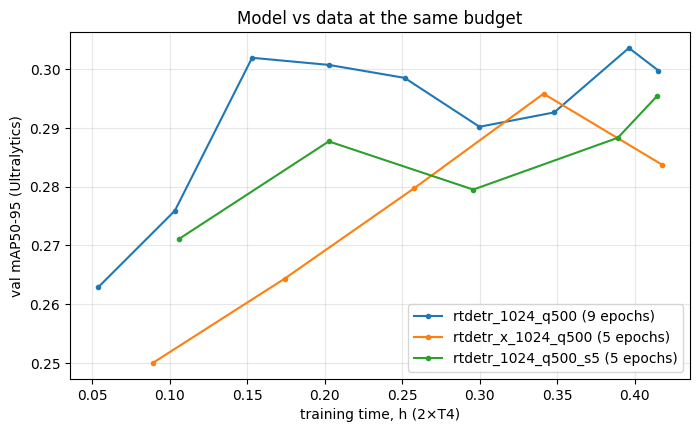

In [7]:
# --- Learning curves of the three runs (Ultralytics validator, no ignore regions) ------------------
plt.figure(figsize=(8, 4.5))
for name in [REF] + list(RUNS):
    d = run_dir(name)
    if d and os.path.exists(f"{d}/results.csv"):
        h = pd.read_csv(f"{d}/results.csv")
        h.columns = h.columns.str.strip()
        x = h["time"] / 3600 if "time" in h else h["epoch"] / h["epoch"].max() * TIME_H
        plt.plot(x, h["metrics/mAP50-95(B)"], "o-", ms=3, label=f"{name} ({len(h)} epochs)")
plt.xlabel("training time, h (2×T4)"); plt.ylabel("val mAP50-95 (Ultralytics)")
plt.title("Model vs data at the same budget"); plt.grid(alpha=.3); plt.legend()
plt.savefig(f"{WORK}/results/final_curves.png", dpi=120, bbox_inches="tight"); plt.show()

## Inference strategy: test input size (no retraining)

The best holdout run is evaluated at three test sizes. RT-DETR has no NMS and Ultralytics offers no test-time augmentation for it, so the input size is the inference setting that matters;
most test clips are 960–1360 px wide (EDA §2), so the question is whether downscaling to 1024 loses small objects.

In [8]:
# --- Select the final validated run and its test input size ---------------------------------------
final_name = max(results, key=lambda n: results[n]["mAP"])
final_cfg = REF_CFG if final_name == REF else RUNS[final_name]
model = RTDETR(weights(final_name))
inf_rows = {}
for size in (896, 1024, 1280):
    gc.collect(); torch.cuda.empty_cache()
    inf_rows[size] = evaluate(model, imgsz=size)
inf = pd.DataFrame(inf_rows).T.rename_axis("test imgsz")
display(inf[["mAP", "AP50", "AP_small", "AP_medium", "AP_large", "AR500", "FPS"]])
best_size = int(inf["mAP"].idxmax())
with open(f"{WORK}/results/inference_config.json", "w") as f:
    json.dump({"run": final_name, "imgsz": best_size}, f)
print(f"final validated run: {final_name}, test imgsz {best_size}")

,mAP,AP50,AP_small,AP_medium,AP_large,AR500,FPS
test imgsz,,,,,,,
896,0.2992,0.5463,0.1498,0.2635,0.5059,0.4799,8.5
1024,0.3167,0.5724,0.1481,0.2815,0.5222,0.4939,7.0
1280,0.3253,0.5921,0.1462,0.2940,0.5199,0.5023,4.9


final validated run: rtdetr_1024_q500, test imgsz 1280


## Final model on all labelled clips

The selected recipe is retrained on all 63 clips (folds 0–4). The time budget is scaled by the number of training frames so the number of epochs stays the same; there is no holdout left, so the last epoch is used.

In [9]:
# --- Retrain the selected recipe on all clips ----------------------------------------------------
full_cfg = {**final_cfg, "folds": "all"}
full_cfg["data"], full_cfg["n_train"] = data_yaml_for(full_cfg["step"], "all")
full_time = round(TIME_H * full_cfg["n_train"] / final_cfg["n_train"], 2)
print(f"final_full: recipe of {final_name}, {full_cfg['n_train']} frames, {full_time} h")
train("final_full", full_cfg, full_time)

final_full: recipe of rtdetr_1024_q500, 2734 frames, 0.52 h
train: Caching images (8.0GB RAM): 100% ━━━━━━━━━━━━ 2734/2734 65.3it/s 41.9s
val: Caching images (1.7GB RAM): 100% ━━━━━━━━━━━━ 573/573 90.8it/s 6.3s


final_full: 0.56 h, 2734 frames


## Summary of all models (same holdout, same evaluator)

mAP  \
family                                run                                    
two-stage anchor-based (Faster R-CNN) frcnn_base                    0.2400   
                                      frcnn_anchors                 0.2319   
                                      frcnn_props                   0.2401   
                                      frcnn_roi                     0.2381   
one-stage anchor-based (RetinaNet)    retina_base                   0.2259   
                                      retina_anchors                0.0519   
                                      retina_anchors_x05            0.1965   
                                      retina_ciou                   0.2256   
one-stage anchor-free (YOLOv8)        v8s_640                       0.1683   
                                      v8s_1024                      0.2238   
                                      v8s_p2_1024                   0.2151   
query-based (RT-DETR)                 rtdetr_640                    0.2424   
                                      rtdetr_1024                   0.3019   
                                      rtdetr_1024_q500              0.3166   
final pipeline (RT-DETR)              rtdetr_x_1024_q500            0.3053   
                                      rtdetr_1024_q500_s5           0.3064   
                                      rtdetr_1024_q500 @ test 1280  0.3253   

                                                                      AP50  \
family                                run                                    
two-stage anchor-based (Faster R-CNN) frcnn_base                    0.4710   
                                      frcnn_anchors                 0.4656   
                                      frcnn_props                   0.4710   
                                      frcnn_roi                     0.4640   
one-stage anchor-based (RetinaNet)    retina_base                   0.4115   
                                      retina_anchors                0.1764   
                                      retina_anchors_x05            0.4088   
                                      retina_ciou                   0.4120   
one-stage anchor-free (YOLOv8)        v8s_640                       0.3240   
                                      v8s_1024                      0.4207   
                                      v8s_p2_1024                   0.4176   
query-based (RT-DETR)                 rtdetr_640                    0.4561   
                                      rtdetr_1024                   0.5514   
                                      rtdetr_1024_q500              0.5723   
final pipeline (RT-DETR)              rtdetr_x_1024_q500            0.5575   
                                      rtdetr_1024_q500_s5           0.5534   
                                      rtdetr_1024_q500 @ test 1280  0.5921   

                                                                    AP_small  \
family                                run                                      
two-stage anchor-based (Faster R-CNN) frcnn_base                      0.0984   
                                      frcnn_anchors                   0.1042   
                                      frcnn_props                     0.1000   
                                      frcnn_roi                       0.0946   
one-stage anchor-based (RetinaNet)    retina_base                     0.0881   
                                      retina_anchors                  0.0601   
                                      retina_anchors_x05              0.0965   
                                      retina_ciou                     0.0879   
one-stage anchor-free (YOLOv8)        v8s_640                         0.0633   
                                      v8s_1024                        0.0918   
                                      v8s_p2_1024                     0.0836   
query-based (RT-DETR)                 rtdetr_640                 

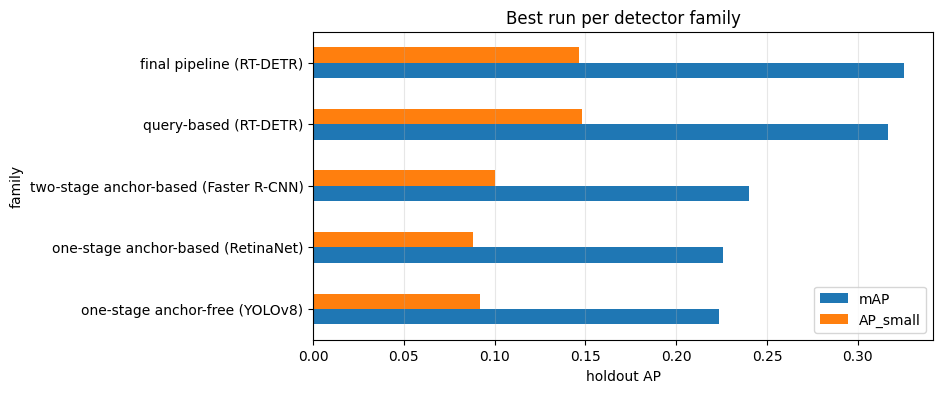

In [10]:
# --- One table with every detector from notebooks 01-05 -------------------------------------------
FAMILIES = {
    "two-stage anchor-based (Faster R-CNN)": ["frcnn_base", "frcnn_anchors", "frcnn_props", "frcnn_roi"],
    "one-stage anchor-based (RetinaNet)":    ["retina_base", "retina_anchors", "retina_anchors_x05", "retina_ciou"],
    "one-stage anchor-free (YOLOv8)":        ["v8s_640", "v8s_1024", "v8s_p2_1024"],
    "query-based (RT-DETR)":                 ["rtdetr_640", "rtdetr_1024", REF],
    "final pipeline (RT-DETR)":              list(RUNS),
}
KEYS = ["mAP", "AP50", "AP_small", "AP_medium", "AP_large", "AR500", "FPS"]
rows = []
for family, names in FAMILIES.items():
    for n in names:
        m = results.get(n) or U.load_result(n)
        if m:
            rows.append({"family": family, "run": n, **{k: m.get(k) for k in KEYS}, "public LB": LB.get(n)})
rows.append({"family": "final pipeline (RT-DETR)", "run": f"{final_name} @ test {best_size}",
             **{k: inf_rows[best_size].get(k) for k in KEYS}, "public LB": LB.get("B_final_validated")})
summary = pd.DataFrame(rows).set_index(["family", "run"])
summary.to_csv(f"{WORK}/results/summary_all_models.csv")
display(summary.round(4))

best_per_family = summary.reset_index().sort_values("mAP").groupby("family", sort=False).tail(1).set_index("family")
ax = best_per_family[["mAP", "AP_small"]].plot.barh(figsize=(8, 4))
ax.set_xlabel("holdout AP"); ax.set_title("Best run per detector family"); ax.grid(alpha=.3, axis="x")
plt.savefig(f"{WORK}/results/summary_best_per_family.png", dpi=120, bbox_inches="tight"); plt.show()

## Test submissions

| file | model | test size | purpose |
|---|---|---|---|
| `submission_A_final_validated_1024.csv` | selected holdout run | 1024 | LB effect of the training change alone (skipped if the selected run is the reference, whose LB is known) |
| `submission_B_final_validated.csv` | selected holdout run | selected | LB effect of the test size; fully validated (skipped if the selected size is 1024, then it equals A) |
| `submission_C_final_full.csv` | `final_full` (all 63 clips) | selected | same recipe with 25 % more clips; not validable on the holdout |

In [11]:
# --- Predict the test set ---------------------------------------------------------------------
test = pd.read_csv(os.path.join(U.comp_root(), "test_images.csv"))

def make_submission(weights_path, tag, imgsz):
    gc.collect(); torch.cuda.empty_cache()
    model = RTDETR(weights_path)
    pred = {image_id: U.prediction_string(*boxes_of(predict(model, os.path.join(U.comp_root(), rel), imgsz)[0]))
            for image_id, rel in zip(test.image_id, test.file_name)}
    path = f"{WORK}/submission_{tag}.csv"
    U.write_submission(pred, path)
    with zipfile.ZipFile(path[:-4] + ".zip", "w", zipfile.ZIP_DEFLATED) as z:
        z.write(path, os.path.basename(path))
    print(f"{tag}: {os.path.getsize(path) / 1e6:.0f} MB csv, {os.path.getsize(path[:-4] + '.zip') / 1e6:.0f} MB zip")

jobs = []
if final_name != REF:
    jobs.append((weights(final_name), "A_final_validated_1024", 1024))
if best_size != 1024:
    jobs.append((weights(final_name), "B_final_validated", best_size))
if run_dir("final_full"):
    jobs.append((weights("final_full", holdout=False), "C_final_full", best_size))
for args in jobs:
    try:
        make_submission(*args)
    except Exception:
        traceback.print_exc()

B_final_validated: 59 MB csv, 17 MB zip
C_final_full: 59 MB csv, 17 MB zip


## Conclusions

| step | run | change | holdout mAP | AP_small | AR500 | public LB |
|---|---|---|---|---|---|---|
| reference (nb 04) | `rtdetr_1024_q500` @ 1024 | – | 0.317 | **0.148** | 0.494 | **0.3414** |
| model | `rtdetr_x_1024_q500` | RT-DETR-L → X | 0.305 | 0.144 | 0.498 | – |
| data | `rtdetr_1024_q500_s5` | step 10 → 5 | 0.306 | 0.144 | 0.500 | – |
| inference | `rtdetr_1024_q500` @ 1280 (B) | test size 1024 → 1280 | **0.325** | 0.146 | **0.502** | 0.3332 |
| data (final) | `final_full` @ 1280 (C) | + 13 holdout clips, last epoch | – | – | – | 0.3145 |

- **Model and data at equal compute: no gain.** Both runs are 0.01 below the reference, about the noise level of a 13-clip holdout. With the time budget fixed, RT-DETR-X (2.2× FLOPs) and the twice larger frame set each got only 5 epochs instead of 9, and both learning curves are still rising at the end of the budget, so they are under-trained rather than worse. A side effect of the fixed recipe: `close_mosaic=5` switched mosaic off for almost all of their 5 epochs, while the reference trained 4 epochs with mosaic. Neither change is worth its cost here; the reference recipe stays.
- **Inference: a holdout gain that does not transfer.** A larger test input (1280) improves the holdout (+0.009 mAP, from medium/large objects, not from small ones) but lowers the public LB by 0.008, while 896 loses on both. RT-DETR stretches every frame to a square input. The holdout is drawn from the labelled clips, 47 of 63 of which are wider than 1360 px (mostly 1904–2688 px), so 1280 brings their objects closer to the scale seen in training; most test clips are only 960–1360 px wide, so at 1024 their objects are already larger than in training and 1280 pushes them further outside the trained scale range. This is the same train/test resolution shift seen for RetinaNet (EDA §2), and it shows that a holdout drawn from the training resolution mix cannot select the test input size reliably.
- **More clips but no checkpoint selection: worse.** Retraining on all 63 clips lowered the LB by another 0.019 (C vs B). Without a holdout, the last epoch has to be used, while every holdout run keeps its best epoch. RT-DETR's validation mAP jumps by up to 0.04 between consecutive epochs in this short budget (notebook 04 curves), so an unselected last epoch can easily cost more than 25 % more clips bring. For an unstable short training run, a validated checkpoint was worth more than extra data.